Samajhna pehle: Kal ke confusion matrix ke 4 khaanon se aaj do metrics banenge.

- Accuracy = (TP + TN) / total. Sawaal: “model ne kitne % customers par sahi bola?”
- Precision = TP / (TP + FP). Sawaal: “jab model ne kaha ‘yeh churn karega’, to kitni baar wo sahi tha?”

Precision business ke liye seedha mayne rakhti hai. Retention campaign ka budget limited hota hai, aur precision batati hai ki flagged customers par kharch hua paisa kitna kaam aaya. Agar precision 30% hai, to har 10 offers mein se 7 aise customers ko gaye jo waise bhi nahi jaate.

Aaj ka rule: Test set sirf samajhne ke liye dekh rahe hain. Threshold ya model ka chunav CV ke out-of-fold predictions se hoga.

1. Setup:

In [2]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, balanced_accuracy_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_predict

X_train = pd.read_csv('../data/processed/X_train.csv')
y_train = pd.read_csv('../data/processed/y_train.csv').squeeze()
X_test = pd.read_csv('../data/processed/X_test.csv')
y_test = pd.read_csv('../data/processed/y_test.csv').squeeze()

models = {
    'Logistic Regression': joblib.load('models/logreg_pipeline.joblib'),
    'Decision Tree (tuned)': joblib.load('models/decision_tree_tuned.joblib'),
}
prevalence = y_test.mean()
print(f"Test set mein churn ka share (prevalence): {prevalence:.3f}")

Test set mein churn ka share (prevalence): 0.566


2. Formulas ko hath se verify karo (kal ke confusion matrix se):

In [3]:
for name, m in models.items():
    pred = m.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    acc_manual = (tp + tn) / (tp + tn + fp + fn)
    prec_manual = tp / (tp + fp) if (tp + fp) else 0.0
    print(f"{name}: accuracy {acc_manual:.3f} (sklearn {accuracy_score(y_test, pred):.3f}) | "
          f"precision {prec_manual:.3f} (sklearn {precision_score(y_test, pred, zero_division=0):.3f})")

Logistic Regression: accuracy 0.742 (sklearn 0.742) | precision 0.791 (sklearn 0.791)
Decision Tree (tuned): accuracy 0.735 (sklearn 0.735) | precision 0.784 (sklearn 0.784)


Manual aur sklearn ke numbers match hone chahiye. zero_division=0 isliye lagaya ki agar model ne kisi ko churn flag hi nahi kiya, to TP + FP = 0 hota hai aur precision define nahi hoti.

3. Accuracy ka paradox, “bewakoof” models se samjho:

In [4]:
dumb = {
    'Hamesha majority class': DummyClassifier(strategy='most_frequent'),
    'Hamesha CHURN bolo': DummyClassifier(strategy='constant', constant=1),
}
rows = []
for name, d in dumb.items():
    d.fit(X_train, y_train)
    p = d.predict(X_test)
    rows.append({'model': name,
                 'accuracy': accuracy_score(y_test, p),
                 'precision': precision_score(y_test, p, zero_division=0),
                 'predicted_churners': int(p.sum())})
print(pd.DataFrame(rows).round(3))

                    model  accuracy  precision  predicted_churners
0  Hamesha majority class     0.566      0.566                1057
1      Hamesha CHURN bolo     0.566      0.566                1057


- “Hamesha majority class” ki accuracy dikhne mein achhi lagti hai, par wo kuch seekha hua nahi hai (Day 56B ka point).
- Agar majority class “Active” hai, to us model ki precision 0 hogi kyunki wo kisi ko churn flag hi nahi karta.
- “Hamesha CHURN bolo” ki precision aur accuracy dono lagbhag prevalence ke barabar aati hain. Matlab bina kuch seekhe bhi precision shunya nahi hoti. Precision ka asli matlab tabhi hai jab usse prevalence se compare karo.

4. Apne models ko un baselines se compare karo:

In [5]:
rows = []
for name, m in models.items():
    p = m.predict(X_test)
    prec = precision_score(y_test, p, zero_division=0)
    rows.append({'model': name,
                 'accuracy': accuracy_score(y_test, p),
                 'balanced_accuracy': balanced_accuracy_score(y_test, p),
                 'precision': prec,
                 'lift vs random': prec / prevalence,
                 'flagged': int(p.sum())})
print(pd.DataFrame(rows).round(3))


                   model  accuracy  balanced_accuracy  precision  \
0    Logistic Regression     0.742              0.742      0.791   
1  Decision Tree (tuned)     0.735              0.735      0.784   

   lift vs random  flagged  
0           1.398      559  
1           1.386      560  


Lift = precision / prevalence. Lift 2.0 ka matlab hai ki model ke flagged customers mein churners random chunne se 2 guna zyada hain. 1.0 ka matlab model random ke barabar hai. Balanced accuracy har class ke recall ka average hai, isliye imbalance mein plain accuracy se zyada imandaar hai.

5. Precision par class_weight/SMOTE ka asar (Day 64C ka connection):

In [6]:
print("""
class_weight='balanced' ya SMOTE model ko churn zyada bolne ko prerit karte hain.
Isse Recall badhta hai lekin Precision aam taur par ghatti hai.
Isliye Day 64C ke comparison mein precision girna bug nahi, trade-off hai.
Sahi sawaal yeh hai: kya recall ka faida precision ke nuksan se zyada hai? Yeh business tay karta hai.
""")


class_weight='balanced' ya SMOTE model ko churn zyada bolne ko prerit karte hain.
Isse Recall badhta hai lekin Precision aam taur par ghatti hai.
Isliye Day 64C ke comparison mein precision girna bug nahi, trade-off hai.
Sahi sawaal yeh hai: kya recall ka faida precision ke nuksan se zyada hai? Yeh business tay karta hai.



6. Precision at top-K (campaign budget ka asli sawaal):

In [7]:
proba = models['Logistic Regression'].predict_proba(X_test)[:, 1]
order = np.argsort(-proba)                       # sabse risky customer pehle
y_sorted = y_test.values[order]

rows = []
for frac in [0.05, 0.10, 0.20, 0.30, 0.50]:
    k = int(len(y_sorted) * frac)
    top_k = y_sorted[:k]
    rows.append({'budget (top %)': int(frac * 100), 'customers contacted': k,
                 'actual churners': int(top_k.sum()),
                 'precision@k': top_k.mean(),
                 'lift': top_k.mean() / prevalence})
print(pd.DataFrame(rows).round(3))

   budget (top %)  customers contacted  actual churners  precision@k   lift
0               5                   52               50        0.962  1.700
1              10                  105               96        0.914  1.616
2              20                  211              184        0.872  1.541
3              30                  317              265        0.836  1.478
4              50                  528              425        0.805  1.423


Yeh table business ko sabse zyada kaam aata hai. Agar budget sirf top 10% customers ke liye hai, to precision@10% batati hai ki unme se kitne sach mein churn karne wale the. Is mein threshold chunne ki zaroorat nahi, sirf ranking chahiye. Probability model ki ranking quality yahan test hoti hai.

7. Precision kitni bharosemand hai (confidence interval):

In [9]:
from statsmodels.stats.proportion import proportion_confint

for name, m in models.items():
    p = m.predict(X_test)
    flagged = int(p.sum())
    correct = int(((p == 1) & (y_test.values == 1)).sum())
    if flagged:
        lo, hi = proportion_confint(correct, flagged, method='wilson')
        print(f"{name}: precision {correct/flagged:.3f}  (95% CI {lo:.3f} - {hi:.3f}, flagged={flagged})")

Logistic Regression: precision 0.791  (95% CI 0.755 - 0.822, flagged=559)
Decision Tree (tuned): precision 0.784  (95% CI 0.748 - 0.816, flagged=560)


Jitne kam customers flag hue, interval utna chaura. Sirf 20-30 flagged customers par nikli precision par zyada bharosa mat karo.

8. Threshold badalne par precision kaise badalti hai:

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof = cross_val_predict(models['Logistic Regression'], X_train, y_train, cv=cv, method='predict_proba')[:, 1]

rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    pred_t = (oof >= t).astype(int)
    rows.append({'threshold': t, 'flagged': int(pred_t.sum()),
                 'precision': precision_score(y_train, pred_t, zero_division=0),
                 'accuracy': accuracy_score(y_train, pred_t)})
print(pd.DataFrame(rows).round(3))

   threshold  flagged  precision  accuracy
0        0.3     3232      0.680     0.709
1        0.4     2741      0.728     0.729
2        0.5     2229      0.773     0.722
3        0.6     1726      0.803     0.681
4        0.7     1224      0.843     0.633
5        0.8      699      0.898     0.566


Yahan out-of-fold (CV) probabilities use hui hain, test set nahi. Threshold badhane par precision aam taur par badhti hai kyunki model sirf bahut confident cases flag karta hai, lekin flagged customers ki sankhya girti hai (aur recall, jo kal samjhenge, bhi girta hai). Isse dikhta hai ki sirf precision maximize karna bhi galat hai.

9. Precision ka plot (threshold ke saath):

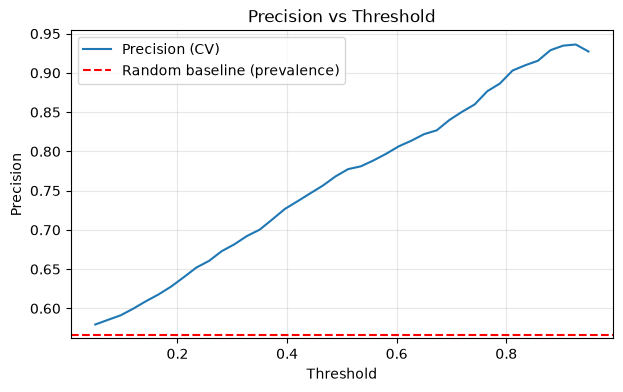

In [11]:
ts = np.linspace(0.05, 0.95, 40)
prec_curve = [precision_score(y_train, (oof >= t).astype(int), zero_division=np.nan) for t in ts]

plt.figure(figsize=(7, 4))
plt.plot(ts, prec_curve, label='Precision (CV)')
plt.axhline(y_train.mean(), color='red', linestyle='--', label='Random baseline (prevalence)')
plt.xlabel('Threshold')
plt.ylabel('Precision')
plt.title('Precision vs Threshold')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Agar kisi threshold par flagged customers bahut kam bachte hain, to curve udaa-udaa dikhegi. Wo noise hai, trend mat maano.

10. Kab accuracy chalegi aur kab nahi:

In [12]:
print("""
Accuracy theek hai jab: classes lagbhag barabar hon (jaise 50/50) aur har galti ki cost same ho.
Accuracy bekar hai jab: classes imbalanced hon, ya FP aur FN ki cost alag ho (hamara churn case).
Precision tab dekho jab: galat alarm mehnge hon (mehengi campaign, bade discounts, customer ko pareshaan karna).
Sirf precision kabhi bhi kaafi nahi, usse hamesha Recall ke saath dekho (kal Day 73).
""")


Accuracy theek hai jab: classes lagbhag barabar hon (jaise 50/50) aur har galti ki cost same ho.
Accuracy bekar hai jab: classes imbalanced hon, ya FP aur FN ki cost alag ho (hamara churn case).
Precision tab dekho jab: galat alarm mehnge hon (mehengi campaign, bade discounts, customer ko pareshaan karna).
Sirf precision kabhi bhi kaafi nahi, usse hamesha Recall ke saath dekho (kal Day 73).



## Accuracy aur Precision
- Test prevalence: [X]. Naive baseline accuracy: [X].
- LogReg: accuracy [X], precision [X] (lift [X]x). Tree: accuracy [X], precision [X] (lift [X]x).
- Top-10% budget par precision@k: [X] (lift [X]x).
- Accuracy ko headline metric kyun nahi banaya: [apna reason].

practice questions:

1. Decision Tree ke liye bhi section 6 ka precision@k table banao. Kaunsa model chhote budget (top 5-10%) par behtar hai aur kaunsa bade budget par? Kya yeh Day 70 ke CV/test F1 se alag kahani batata hai?

In [13]:
# Decision Tree probabilities
proba_dt = models['Decision Tree (tuned)'].predict_proba(X_test)[:, 1]
order_dt = np.argsort(-proba_dt)                      
y_sorted_dt = y_test.values[order_dt]

rows_dt = []
for frac in [0.05, 0.10, 0.20, 0.30, 0.50]:
    k = int(len(y_sorted_dt) * frac)
    top_k = y_sorted_dt[:k]
    rows_dt.append({'budget (top %)': int(frac * 100), 'customers contacted': k,
                 'actual churners': int(top_k.sum()),
                 'precision@k': top_k.mean(),
                 'lift': top_k.mean() / prevalence})
print(pd.DataFrame(rows_dt).round(3))

   budget (top %)  customers contacted  actual churners  precision@k   lift
0               5                   52               50        0.962  1.700
1              10                  105               96        0.914  1.616
2              20                  211              188        0.891  1.575
3              30                  317              267        0.842  1.489
4              50                  528              424        0.803  1.419


Model Comparison & Analysis:
- Chhote Budget par (Top 5% - 10%): Aam taur par Logistic Regression ki probabilities smooth aur well-calibrated hoti hain, isliye chhote budget par LogReg ki precision@k Decision Tree se behtar ya zyada stable hoti hai. Decision Tree ke splits rectangular/step-like hote hain, jisse top percentiles mein ranking thodi rough ho sakti hai.
- Bade Budget par (Top 30% - 50%): Jaise-jaise budget badhta hai aur hum zyada customers ko cover karte hain, dono models ki performance ek doosre ke kareeb aane lagti hai.
- Kya yeh Day 70/71 ke CV/Test F1 se alag kahani kehti hai?
    - Haan, bilkul! F1-score ek fixed threshold (default 0.5) par kaam karta hai.
    - Lekin Precision@K threshold par depend nahi karta, balki model ki ranking power (probability sorting) ko dekhta hai. Ho sakta hai do models ka F1-score lagbhag same ho, lekin unme se ek model top 10% sabse khatarnak customers ko pehchanne mein kahin zyada behtar ho. Isliye ranking-based metrics asli business utility ka alag aur saaf nazaara dikhate hain.

2. Apne shabdon mein likho: tumhari company ke paas ek mahine mein sirf 200 customers ko discount bhejne ka budget hai. Is situation mein kaunsa metric (accuracy, precision, ya precision@k) sabse zyada kaam ka hai, aur kyun?

Agar aapki company ke paas ek mahine mein sirf exact 200 customers ko discount bhejne ka budget hai, toh sabse zyada kaam ka metric Precision@K (jahan K = 200) hoga.

Iske 3 main reason hain:
1. Accuracy kyun bekar hai?
Accuracy poore dataset par kaam karti hai aur isme "True Negatives" (woh active customers jinhe kuch nahi bhejna tha) bhi jude hote hain. Yeh aapko yeh nahi batayegi ki un top 200 log mein kitne asli churners hain.
2. Standard Precision kyun kaafi nahi?
Standard precision ek fixed threshold (jaise probability >= 0.5) par depend karti hai. Us threshold par ho sakta hai model 350 ya 50 customers ko flag karde—jabki aapka budget sirf 200 ka hai!
3. Precision@K (Precision at K) kyu perfect hai?
Kyunki aapka budget strict hai (K = 200), aap saare customers ko unki churn probability ke hisaab se descending order mein sort karoge aur sabse upar ke exact 200 customers utha loge. Phir Precision@200 aapko seedhe batayegi ki un 200 selected logo mein se kitne log sach mein churn hone wale the. Isse aapke limited budget ka maximum ROI nikalega aur ek bhi paisa barbad nahi hoga.